In [8]:
!pip install matplotlib

In [1]:
import random
import numpy as np 
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
from grad.engine import Value
from grad.nn import Neuron, Layer, MLP

In [3]:
np.random.seed(1337)
random.seed(1337)

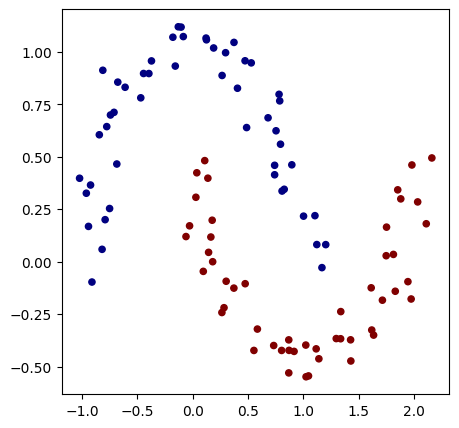

In [4]:
# make up a data set 

from sklearn.datasets import make_moons, make_blobs
X, y = make_moons(n_samples=100, noise=0.1)


y = y*2 - 1 # make y be -1 or 1
# visualize in 2D
plt.figure(figsize=(5,5))
plt.scatter(X[:,0], X[:,1], c=y, s=20, cmap='jet')

In [5]:
model = MLP(2, [16, 16, 1])
print(model)
print("Number of parameters:", len(model.parameters()))

MLP of [Layer of [TanhNeuron(2), TanhNeuron(2), TanhNeuron(2), TanhNeuron(2), TanhNeuron(2), TanhNeuron(2), TanhNeuron(2), TanhNeuron(2), TanhNeuron(2), TanhNeuron(2), TanhNeuron(2), TanhNeuron(2), TanhNeuron(2), TanhNeuron(2), TanhNeuron(2), TanhNeuron(2)], Layer of [TanhNeuron(16), TanhNeuron(16), TanhNeuron(16), TanhNeuron(16), TanhNeuron(16), TanhNeuron(16), TanhNeuron(16), TanhNeuron(16), TanhNeuron(16), TanhNeuron(16), TanhNeuron(16), TanhNeuron(16), TanhNeuron(16), TanhNeuron(16), TanhNeuron(16), TanhNeuron(16)], Layer of [TanhNeuron(16)]]
Number of parameters: 337


In [15]:
def loss(batch_size=None): 

    if batch_size is None:
        Xb, yb = X, y
    else: 
        ri = np.random.permutation(X.shape[0])[:batch_size]
        Xb, yb = X[ri], y[ri]
    inputs = [list(map(Value, xrow)) for xrow in Xb]

    # forward the model to get scores
    scores = list(map(model, inputs))  
    
    # svm max_margin loss
    # losses = [(1 + -yi*scorei).relu() for yi, scorei in zip(yb, scores)]
    # MSE tanh
    losses = [(scorei - yi)**2 for yi, scorei in zip(yb, scores)]
    data_loss = sum(losses) * (1.0 / len(losses))
    
    # L2 regularization
    alpha= 1e-4
    reg_loss = alpha * sum(p*p for p in model.parameters())
    total_loss = data_loss + reg_loss

    # get the accuracy
    accuracy = [(yi > 0) == (scorei.data > 0) for yi, scorei in zip(yb, scores)]
    return total_loss, sum(accuracy) / len(accuracy)

total_loss, acc = loss()
print(total_loss, acc)

Value(data=0.20026239508006413) 0.92


In [16]:
for k in range(100): 

    # forward pass
    total_loss, acc = loss()

    #backward
    model.zero_grad()
    total_loss.backward()

    # update sgd
    learning_rate = 1.0 - 0.9*k/100
    for p in model.parameters():
        p.data -= learning_rate * p.grad

    if k % 1 == 0:
        print(f"step {k} loss {total_loss.data}, accuracy {acc*100}%")

step 0 loss 0.20026239508006413, accuracy 92.0%
step 1 loss 0.32092409461305804, accuracy 90.0%
step 2 loss 0.541400080511124, accuracy 84.0%
step 3 loss 0.36609181429440185, accuracy 89.0%
step 4 loss 0.08590977089063417, accuracy 97.0%
step 5 loss 0.21356256148797134, accuracy 95.0%
step 6 loss 0.30956584885999455, accuracy 91.0%
step 7 loss 0.6962638721397012, accuracy 83.0%
step 8 loss 0.5600190695469386, accuracy 85.0%
step 9 loss 0.35524781053933696, accuracy 90.0%
step 10 loss 0.1935339835748246, accuracy 93.0%
step 11 loss 0.04292521011423746, accuracy 99.0%
step 12 loss 0.048801065141989494, accuracy 100.0%
step 13 loss 0.1836697549993848, accuracy 95.0%
step 14 loss 0.05506639611974871, accuracy 98.0%
step 15 loss 0.2319283134641496, accuracy 92.0%
step 16 loss 0.6661422984981308, accuracy 84.0%
step 17 loss 0.6306881446920646, accuracy 84.0%
step 18 loss 0.5704748764282792, accuracy 85.0%
step 19 loss 0.35500173309069766, accuracy 91.0%
step 20 loss 0.22118807693791853, accu

(-1.548639298268643, 1.951360701731357)

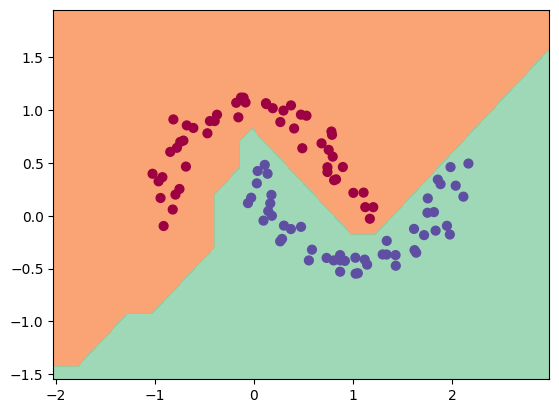

In [17]:
h = 0.25
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))
Xmesh = np.c_[xx.ravel(), yy.ravel()]
inputs = [list(map(Value, xrow)) for xrow in Xmesh]
scores = list(map(model, inputs))
Z = np.array([s.data > 0 for s in scores])
Z = Z.reshape(xx.shape)

fig = plt.figure()
plt.contourf(xx, yy, Z, cmap=plt.cm.Spectral, alpha=0.8)
plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.Spectral)
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())